# Neural Black-Scholes solvers - A comparison

This sections presents the implementation of two neural solvers of the Black-Scholes equation (BS) written as a BSDE and solved with a neural solver under the Deep BSDE protocol. This notebook finds the fair price of an geometric basket option. It is used because it has a closed form solution and the methods can easily be compared. Altough additional payoff functions (terminal conditions) are includeed and can be swapped, altough these lack exact solution. The basket option is assumened to be uncorrelated (for simplicity). The two methods compared is the vanilla single point Deep BSDE with subnets and the adjusted shared net single point Deep BSDE. 

The notebook investigates how model parameters grow as a function of $N$, training times for such networks, accuracy under a fixed budget and convergence time for a tolerance. 

In [167]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

Consider the multidimensional BS, expressed as 
\begin{equation}
    \partial_t u + \tfrac{1}{2}\operatorname{Tr}\!\big(\sigma\sigma^{\top}\nabla^2 u\big) + \mu\cdot\nabla u - ru = 0,
\qquad u(T,S) = g(S) = \Big((\Pi_{i=1} S^i)^{1/d} - K\Big)^{+}
\end{equation}
The SDE can be defined as 
\begin{equation}
    dS_t = \operatorname{diag}(r-q)\,S_t\,dt + \operatorname{diag}(S_t)\operatorname{diag}(\sigma)\,dW_t,
\end{equation}
In this implementation we consider $d = 100$, $K = 100$, $\xi = 100$, $\sigma = 1$, $T=1$, $t = 0$, $N = 20$, $\Delta t = T/N$, $r = 0.05$ and $q = 0$ for the Deep BSDE solvers.

The exact solution for the geometric basket call is defined as

\begin{equation}
\mathbb{E}_t[G(T)] = \exp\left( \sum_{i=1}^n w_i \ln S_i(t) + \left( \sum_{i=1}^n w_i (r - q_i) - \frac{1}{2} \sigma_G^2 \right) (T - t) \right)
\end{equation}

In [168]:
from scipy.stats import norm

def geo_basket_call(S0, K, r, q, sigma, rho, T):
    """S0, q, sigma: arrays of shape (d,); rho: (d, d) correlation matrix."""
    S0, q, sigma = map(np.asarray, (S0, q, sigma))
    d = len(S0)
    sig_G2 = sigma @ rho @ sigma / d**2                      # variance of the log geometric mean
    mu_G = np.mean(np.log(S0) + (r - q - 0.5 * sigma**2) * T)
    F = np.exp(mu_G + 0.5 * sig_G2 * T)                      # forward of the geometric mean
    s = np.sqrt(sig_G2 * T)
    d1 = (np.log(F / K) + 0.5 * s**2) / s
    d2 = d1 - s
    return np.exp(-r * T) * (F * norm.cdf(d1) - K * norm.cdf(d2))

The stochastic process can be integrated as $Y_{n+1} = Y_n - f(t_n, S_n, Y_n, Z_n)\,\Delta t + Z_n^\top \Delta W_n = Y_n + r\,Y_n\,\Delta t + Z_n^\top \Delta W_n$

Since $f = -ru \to f = - r Y_n$, and familiarly $Z_n = \sigma^{\top} \nabla u(n, X_n)$

Both methods use the same path sampling. Since $X_t$ and $W_t$ do not require a computational graph and are not used to update the network, they can be sampled all at once (for a batch) and seperatly, outside the network.

In [169]:
def sample_paths(xi, bs, d, N, dt, r=0.05, q=0.0, sigma=0.2):
    dW = np.sqrt(dt) * np.random.randn(bs, N, d)
    log_incr = (r - q - 0.5 * sigma**2) * dt + sigma * dW
    X = np.empty((bs, N + 1, d))
    X[:, 0] = xi
    X[:, 1:] = xi * np.exp(np.cumsum(log_incr, axis=1))
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)


r = 0.05
def fun(Y):
    return -r*Y

K = 100.0
def g_geo(x):  # geometric basket call (closed form exists)
    return (x.log().mean(-1).exp() - K).clamp(min=0)

def g_ari(x):
    pass

The simulation of the paths can be visualized in a graph

/var/folders/9x/q5ftyh0d39nd36l_8835rszw0000gn/T/ipykernel_72275/3753842239.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


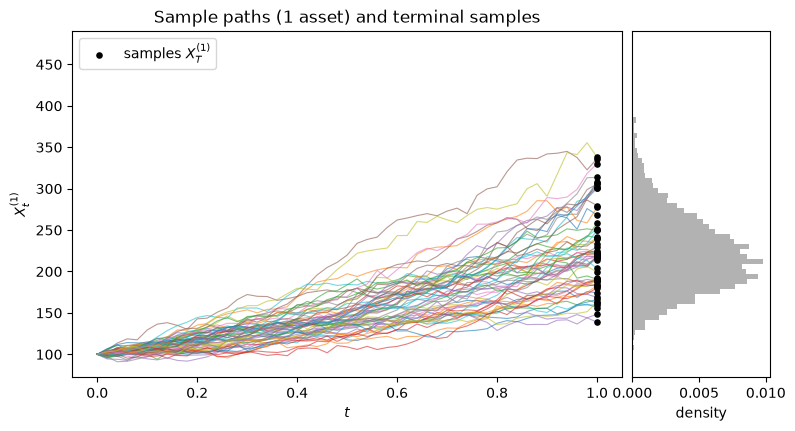

In [ ]:
# Illustration parameters
xi, d, T, N = 100.0, 1, 1.0, 50
dt = T / N
bs_show, bs_hist = 60, 5000           # paths drawn, samples in histogram

X, _ = sample_paths(xi, bs_hist, d, N, dt, r = 0.1)
X = X[:, :, 0].numpy()                # first asset, shape (bs, N+1)
t = np.linspace(0, T, N + 1)
X_T = X[:, -1]

fig, (ax, axh) = plt.subplots(
    1, 2, sharey=True, figsize=(9, 4.5),
    gridspec_kw={"width_ratios": [4, 1], "wspace": 0.03},
)

ax.plot(t, X[:bs_show].T, lw=0.8, alpha=0.6)
ax.scatter(np.full(bs_show, T), X_T[:bs_show], s=14, color="k", zorder=3,
           label=r"samples $X_T^{(1)}$")
ax.set_xlabel("$t$")
ax.set_ylabel(r"$X_t^{(1)}$")
ax.set_title("Sample paths (1 asset) and terminal samples")
ax.legend(loc="upper left")

axh.hist(X_T, bins=60, orientation="horizontal", density=True,
         color="gray", alpha=0.6)
axh.set_xlabel("density")
axh.tick_params(left=False)

plt.tight_layout()
plt.show()


In the original Deep BSDE network, each increment in time corresponds to its own neural network estimating $Z_t$. So called subnets to the full NN and are represented by a module. The full net and consequently each subnet is updated after each batch of 64-128 paths are run. The paths are run forward in time and starts at $Y_0 = \theta_y$ (a trainable parameter).

The shared network methodology instead implements one shared NN that is continously updated under the same loss function. This network should be more sparse, but the question is if it can match performance of the original Deep BSDE under a leaner computational budget.


The loss funtion is familiarly
\begin{equation}
    \mathcal{L}(\theta) = \frac{1}{M} \sum_{m = 1}^M |Y_N^{(m)} - g(X_N^{(m)})|^2 = \mathbb{E}[|Y_T - g(X_T)|^2]
\end{equation}


In [171]:
class SubNet(nn.Module):
    """ Subnet for each time increment Z_t, takes dimension and width as arguments.
    Typically, width = d + 10
    """
    def __init__(self, d, width):
        super().__init__()
        self.net = nn.Sequential(nn.BatchNorm1d(d),
            nn.Linear(d, width),
            nn.BatchNorm1d(width),
            nn.ELU(),
            nn.Linear(width, width),
            nn.BatchNorm1d(width),
            nn.ELU(),
            nn.Linear(width, d),
        )
    def forward(self, x):
        return self.net(x)


class YZnet(nn.Module):
    def __init__(self, d, dt, N, f, y0_init=(0., 1.)):
            super().__init__()
            self.N, self.dt, self.f = N, dt, f
            self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
            self.z0 = nn.Parameter(torch.empty(d).uniform_(-1,1))
            self.subnets = nn.ModuleList([SubNet(d, d+10) for _ in range(N-1)])
    def forward(self, X, dW):
        M = X.shape[0]
        y = self.y0.expand(M)
        z = self.z0.expand(M, -1)
        for n in range(self.N):
            t = n*self.dt
            y = y - self.f(y) * self.dt + (z*dW[:,n]).sum(-1)
            if n < self.N-1:
                z = self.subnets[n](X[:, n + 1])
        return y


In [172]:
class ZNet(nn.Module):
    """One network Z(t, x) shared over all time steps (Chan-Wai-Nam et al., 'FC Merged')."""
    def __init__(self, d, width, T, x_mean, x_std):
        super().__init__()
        self.T = T
        self.register_buffer("x_mean", torch.as_tensor(x_mean, dtype=torch.float32))
        self.register_buffer("x_std", torch.as_tensor(x_std, dtype=torch.float32))
        self.net = nn.Sequential(
            nn.Linear(d + 1, width), nn.ELU(), # Uses ELU instead of ReLU
            nn.Linear(width, width), nn.ELU(),
            nn.Linear(width, d),
        )

    def forward(self, t, x):
        # standardizes input, instead of batchnorm. 
        x = (x - self.x_mean) / self.x_std
        t = torch.full_like(x[:, :1], 2 * t / self.T - 1)   # time scaled to [-1, 1]
        return self.net(torch.cat([x, t], dim=1))


class YZnet_shared(nn.Module):
    def __init__(self, d, dt, N, f, x_mean, x_std, y0_init=(0., 1.)):
        super().__init__()
        self.N, self.dt, self.f = N, dt, f
        self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
        self.z0 = nn.Parameter(torch.empty(d).uniform_(-1, 1))
        self.znet = ZNet(d, d + 10, N * dt, x_mean, x_std)

    def forward(self, X, dW):
        M = X.shape[0]
        y = self.y0.expand(M)
        z = self.z0.expand(M, -1)
        for n in range(self.N):
            y = y - self.f(y) * self.dt + (z * dW[:, n]).sum(-1)
            if n < self.N - 1:
                # Model now takes t as a parameter as well since it is not discretized in subnets 
                z = self.znet((n + 1) * self.dt, X[:, n + 1])
        return y

Here, the model and optimizer is set up. In this case ADAM is used, but SGD could also be used as in the original paper.

In [173]:
T = 1.0
N = 20
dt = T/N
d = 10
S0 = np.full(d, 100.0)

X_pilot, _ = sample_paths(xi=S0, bs=10_000, d=d, N=N, dt=dt)   # X: (M, N+1, d)
x_mean = X_pilot.mean(dim=(0, 1))
x_std  = X_pilot.std(dim=(0, 1)) + 1e-8

orig_model   = YZnet(d=d, dt=dt, N=N, f=fun)
merged_model = YZnet_shared(d=d, dt=dt, N=N, f=fun, x_mean=x_mean, x_std=x_std)

def make_opt(model, lr_y0=1e-2, lr_z=1e-3):
    """Separate learning rates: a larger one for the scalar y0, a smaller one for the Z networks."""
    y0_params = [model.y0]
    z_params  = [p for name, p in model.named_parameters() if name != "y0"]
    return torch.optim.Adam([
        {"params": y0_params, "lr": lr_y0},
        {"params": z_params,  "lr": lr_z},
    ])

orig_opt   = make_opt(orig_model)
merged_opt = make_opt(merged_model)

The loss and train functions are defined

In [174]:
def loss_fn(model, X, dW):
    return ((model(X, dW) - g_geo(X[:, -1]))**2).mean()

def train(model, opt, batch_size, n_iter, d, N, dt, xi, verbose: bool = True):
    y0_hist = np.zeros(n_iter)
    loss_hist = np.zeros(n_iter)
    for i in range(n_iter):
        opt.zero_grad()

        X, dW = sample_paths(xi, batch_size, d=d, N=N, dt=dt )

        loss = loss_fn(model, X, dW)
        loss.backward()
        opt.step()

        loss_hist[i] = loss.item()
        y0_hist[i] = model.y0.item()
        
        if verbose and i % 100 == 0:
            print(f"iter {i:5d} | loss {loss_hist[i]:.4f} | Y0 {y0_hist[i]:.4f}")
    return loss_hist, y0_hist

def train_tol(model, opt, batch_size, tol, d, N, dt, xi, exact,
              patience=5, max_iter=5000, verbose: bool = True):

    y0_hist, loss_hist = [], []
    count = 0
    n_conv = None

    for n_iter in range(1, max_iter + 1):
        opt.zero_grad()
        X, dW = sample_paths(xi, batch_size, d=d, N=N, dt=dt)
        loss = loss_fn(model, X, dW)
        loss.backward()
        opt.step()

        y0 = model.y0.item()
        loss_hist.append(loss.item())
        y0_hist.append(y0)

        # Count only consecutive iterations inside the tolerance band
        count = count + 1 if abs(y0 - exact) < tol else 0
        if count >= patience:
            n_conv = n_iter - patience + 1   # first iteration of the in-band run
            break

        if verbose and n_iter % 100 == 0:
            print(f"iter {n_iter:5d} | loss {loss_hist[-1]:.4f} | Y0 {y0_hist[-1]:.4f}")

    if verbose:
        msg = f"converged at iter {n_conv}" if n_conv else f"did not converge in {max_iter} iters"
        print(msg + f" | Y0 {y0_hist[-1]:.4f} | exact {exact:.4f}")
    return loss_hist, y0_hist, n_conv


For a geometric basket call the exact price can be found

In [175]:
price = geo_basket_call(S0=np.full(d, 100.0), K=100.0, r=0.05, q=np.zeros(d),
                        sigma=np.full(d, 0.2), rho=np.eye(d), T=1.0)

For comparison, the MC method (established in other notebooks) is implemented. Note that since there is no discretization error, here $N=1$ for MC

Now the model can be trained

In [176]:

orig_loss_hist, orig_y0_hist = train(model=orig_model, opt=orig_opt, batch_size=128, n_iter=1200, d=d, N=N, dt=dt, xi=S0)
print(f"Y0 = {orig_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")

merged_loss_hist, merged_y0_hist = train(model=merged_model, opt=merged_opt, batch_size=128, n_iter=1200, d=d, N=N, dt=dt, xi=S0)
print(f"Y0 = {merged_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")


iter     0 | loss 31.7902 | Y0 0.6826
iter   100 | loss 31.0966 | Y0 1.6336
iter   200 | loss 26.9796 | Y0 2.4216
iter   300 | loss 19.2543 | Y0 3.0574
iter   400 | loss 13.8989 | Y0 3.5171
iter   500 | loss 5.3914 | Y0 3.8547
iter   600 | loss 5.0739 | Y0 4.0657
iter   700 | loss 2.6131 | Y0 4.1837
iter   800 | loss 2.6387 | Y0 4.2453
iter   900 | loss 1.8160 | Y0 4.2702
iter  1000 | loss 1.2726 | Y0 4.2919
iter  1100 | loss 1.3660 | Y0 4.2902
Y0 = 4.2910, exact u(0, xi) = 4.2908
iter     0 | loss 45.4230 | Y0 0.1748
iter   100 | loss 17.0784 | Y0 1.1240
iter   200 | loss 8.2044 | Y0 1.9447
iter   300 | loss 5.4890 | Y0 2.6322
iter   400 | loss 3.4190 | Y0 3.1682
iter   500 | loss 2.3901 | Y0 3.5724
iter   600 | loss 1.8833 | Y0 3.8549
iter   700 | loss 1.5311 | Y0 4.0416
iter   800 | loss 1.4584 | Y0 4.1596
iter   900 | loss 1.2246 | Y0 4.2220
iter  1000 | loss 1.0950 | Y0 4.2583
iter  1100 | loss 0.9327 | Y0 4.2910
Y0 = 4.2952, exact u(0, xi) = 4.2908


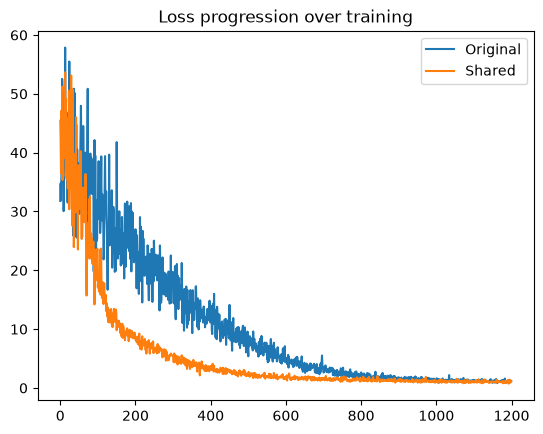

In [177]:
plt.plot(orig_loss_hist, label = "Original")
plt.plot(merged_loss_hist, label = "Shared")
plt.title("Loss progression over training")
plt.legend()
plt.show()

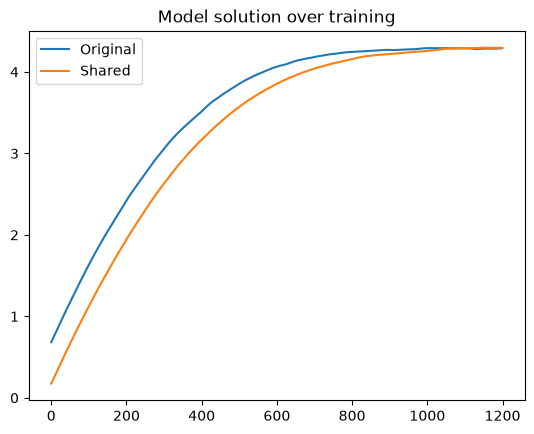

In [178]:
plt.plot(orig_y0_hist, label = 'Original')
plt.plot(merged_y0_hist, label = 'Shared')
plt.title("Model solution over training")
plt.legend()
plt.show()

In [179]:
orig_model   = YZnet(d=d, dt=dt, N=N, f=fun)
merged_model = YZnet_shared(d=d, dt=dt, N=N, f=fun, x_mean=x_mean, x_std=x_std)
orig_opt     = make_opt(orig_model)
merged_opt   = make_opt(merged_model)

loss_h, y0_h, n_conv = train_tol(orig_model, orig_opt, batch_size=128, tol=0.02,
                                 d=d, N=N, dt=dt, xi=S0, exact=price)
print(f"Y0 = {orig_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")

m_loss_h, m_y0_h, m_n_conv = train_tol(merged_model, merged_opt, batch_size=128, tol=0.02,
                                       d=d, N=N, dt=dt, xi=S0, exact=price)
print(f"Y0 = {merged_model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")


iter   100 | loss 38.3254 | Y0 1.9116
iter   200 | loss 19.4537 | Y0 2.6616
iter   300 | loss 20.5007 | Y0 3.2450
iter   400 | loss 11.2624 | Y0 3.6804
iter   500 | loss 6.3896 | Y0 3.9683
iter   600 | loss 4.8101 | Y0 4.1285
iter   700 | loss 2.8969 | Y0 4.2372
converged at iter 759 | Y0 4.2715 | exact 4.2908
Y0 = 4.2715, exact u(0, xi) = 4.2908
iter   100 | loss 17.4577 | Y0 1.7356
iter   200 | loss 5.6603 | Y0 2.5122
iter   300 | loss 3.3157 | Y0 3.1310
iter   400 | loss 2.3807 | Y0 3.5781
iter   500 | loss 1.7574 | Y0 3.8780
iter   600 | loss 2.1051 | Y0 4.0712
iter   700 | loss 1.3765 | Y0 4.1786
iter   800 | loss 1.3568 | Y0 4.2442
converged at iter 889 | Y0 4.2718 | exact 4.2908
Y0 = 4.2718, exact u(0, xi) = 4.2908


N=  5 | Original |    3.61 s | converged at iter 1005 | Y0 4.2732
N=  5 | Shared   |    1.38 s | converged at iter 1015 | Y0 4.2709
N= 10 | Original |    7.39 s | converged at iter 973 | Y0 4.2727
N= 10 | Shared   |    2.42 s | converged at iter 965 | Y0 4.2728
N= 20 | Original |   17.57 s | converged at iter 1058 | Y0 4.2736
N= 20 | Shared   |    7.29 s | converged at iter 997 | Y0 4.2716
N= 30 | Original |   29.86 s | converged at iter 1004 | Y0 4.2731
N= 30 | Shared   |    7.39 s | converged at iter 965 | Y0 4.2717
N= 40 | Original |   34.40 s | converged at iter 1037 | Y0 4.2719
N= 40 | Shared   |    9.82 s | converged at iter 1025 | Y0 4.2723


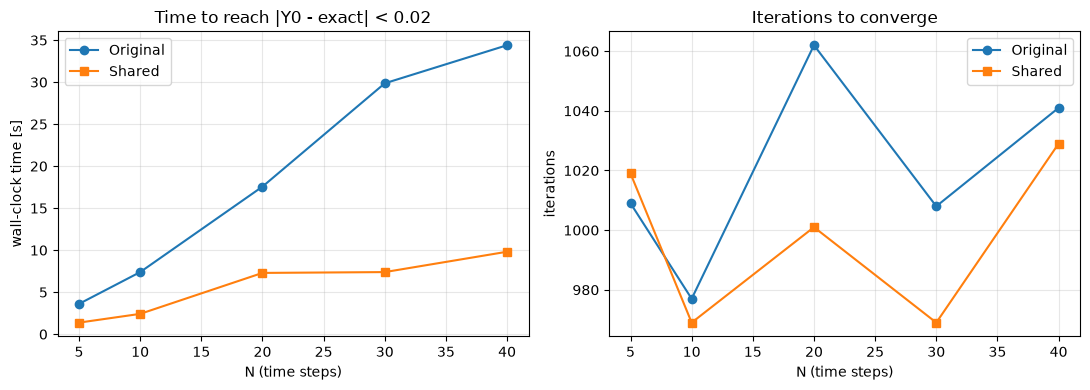

In [180]:
import time

def make_models(N_, seed=0):
    """Fresh models + optimizers for a given N (pilot stats recomputed for the shared net)."""
    dt_ = T / N_
    X_p, _ = sample_paths(xi=S0, bs=2_000, d=d, N=N_, dt=dt_)
    mean_, std_ = X_p.mean(dim=(0, 1)), X_p.std(dim=(0, 1)) + 1e-8
    torch.manual_seed(seed)
    m_orig = YZnet(d=d, dt=dt_, N=N_, f=fun)
    torch.manual_seed(seed)
    m_shared = YZnet_shared(d=d, dt=dt_, N=N_, f=fun, x_mean=mean_, x_std=std_)
    return {"Original": (m_orig, make_opt(m_orig)), "Shared": (m_shared, make_opt(m_shared))}

Ns_time  = [5, 10, 20, 30, 40]
tol      = 0.02
max_iter = 5000
results  = {"Original": {"time": [], "iters": [], "conv": []},
            "Shared":   {"time": [], "iters": [], "conv": []}}

for N_ in Ns_time:
    for name, (model, opt_) in make_models(N_).items():
        np.random.seed(0)                       # same path stream for both models
        t0 = time.perf_counter()
        _, y0_h, n_conv = train_tol(model, opt_, batch_size=128, tol=tol, d=d, N=N_,
                                    dt=T / N_, xi=S0, exact=price,
                                    max_iter=max_iter, verbose=False)
        elapsed = time.perf_counter() - t0
        results[name]["time"].append(elapsed)
        results[name]["iters"].append(len(y0_h))
        results[name]["conv"].append(n_conv is not None)
        status = f"converged at iter {n_conv}" if n_conv else "NOT converged"
        print(f"N={N_:3d} | {name:8s} | {elapsed:7.2f} s | {status} | Y0 {y0_h[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, marker in [("Original", "o"), ("Shared", "s")]:
    res = results[name]
    for ax, key in zip(axes, ["time", "iters"]):
        ax.plot(Ns_time, res[key], marker=marker, label=name)
        # red ring around runs that hit max_iter without converging
        bad = [i for i, c in enumerate(res["conv"]) if not c]
        if bad:
            ax.plot([Ns_time[i] for i in bad], [res[key][i] for i in bad], "o",
                    mfc="none", mec="red", ms=12, ls="none")

axes[0].set(xlabel="N (time steps)", ylabel="wall-clock time [s]",
            title=f"Time to reach |Y0 - exact| < {tol}")
axes[1].set(xlabel="N (time steps)", ylabel="iterations",
            title="Iterations to converge")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

N=   2 | Original        961 | Shared      881 | ratio    1.1
N=   5 | Original      3,811 | Shared      881 | ratio    4.3
N=  10 | Original      8,561 | Shared      881 | ratio    9.7
N=  20 | Original     18,061 | Shared      881 | ratio   20.5
N=  40 | Original     37,061 | Shared      881 | ratio   42.1
N=  60 | Original     56,061 | Shared      881 | ratio   63.6
N=  80 | Original     75,061 | Shared      881 | ratio   85.2
N= 100 | Original     94,061 | Shared      881 | ratio  106.8


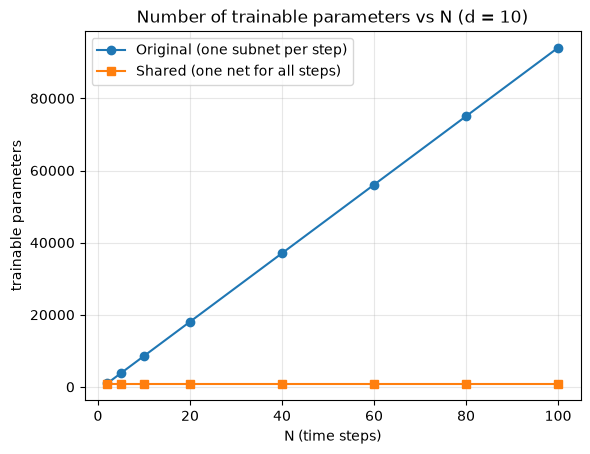

In [181]:
def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Ns = [2, 5, 10, 20, 40, 60, 80, 100]
p_orig, p_shared = [], []
for N_ in Ns:
    dt_ = T / N_
    p_orig.append(n_params(YZnet(d=d, dt=dt_, N=N_, f=fun)))
    p_shared.append(n_params(YZnet_shared(d=d, dt=dt_, N=N_, f=fun, x_mean=x_mean, x_std=x_std)))

for N_, po, ps in zip(Ns, p_orig, p_shared):
    print(f"N={N_:4d} | Original {po:>10,d} | Shared {ps:>8,d} | ratio {po/ps:6.1f}")

plt.plot(Ns, p_orig, "o-", label="Original (one subnet per step)")
plt.plot(Ns, p_shared, "s-", label="Shared (one net for all steps)")
plt.xlabel("N (time steps)")
plt.ylabel("trainable parameters")
plt.title(f"Number of trainable parameters vs N (d = {d})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Discussion / comment

Swapping the original architecture composed of subnets for each time step grows the size of the network as $N$ grows, this in turn demands compute resorces as larger nets take more iterations and longer time to train and update, this creates a negative compute-time spiral. Instead the shared network is introduced which does not grow with the number of timesteps $N$ but is fixed (and has fewer parameters than the original version for every $N$ except $N = 1$). The results from the notebook suggest that the shared model is equally capable (at least in the tests performed here). For a given tolerance the model training time seems to grow linearly with $N$ and is nearly around half the time for the corresponding subnet model. 